# Anomalías en temperatura de una máquina: Evaluación

Detectar desviaciones en una serie de temperatura de máquina del benchmark NAB.

Precisión, recall, F1 y matriz por punto usando las ventanas oficiales de etiquetas. No es la puntuación oficial NAB ni una evaluación de eventos independientes; una avería puede generar muchos puntos alertados.

Consulta la [metodología](../docs/metodologia.md). Los reportes corresponden a la última ejecución de cada etapa.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("nab_anomaly_detection")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from nab_anomaly_detection.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Anomalías en temperatura de una máquina: evaluacion

En test se obtiene **F1 0.0398**, precisión **8.06%** y recall **2.65%**. Hay **567 puntos etiquetados como anómalos**. Métricas por punto dentro de ventanas; no puntuación NAB oficial. La ventana móvil avanza con datos observados, sin consultar etiquetas; un evento puede generar múltiples alertas. Si test no tiene anomalías, recall y F1 se representan como cero por convención y no acreditan capacidad de detección.


,baseline,modelo
casos,4537.0,4537.000000
precision,0.0,0.080645
recall,0.0,0.026455
f1,0.0,0.039841
positivos_reales,567.0,567.000000


,timestamp,value,label,score,prediccion_modelo
0,2014-02-03 21:25:00,98.841761,0,0.139646,0
1,2014-02-03 21:30:00,97.474381,0,1.409547,0
2,2014-02-03 21:35:00,97.492345,0,1.366211,0
3,2014-02-03 21:40:00,98.622080,0,0.217017,0
4,2014-02-03 21:45:00,97.845144,0,0.958358,0
5,2014-02-03 21:50:00,97.469830,0,1.295875,0
6,2014-02-03 21:55:00,98.160064,0,0.562547,0
7,2014-02-03 22:00:00,98.167624,0,0.522757,0
8,2014-02-03 22:05:00,98.291992,0,0.360554,0
9,2014-02-03 22:10:00,96.526547,0,2.189503,0


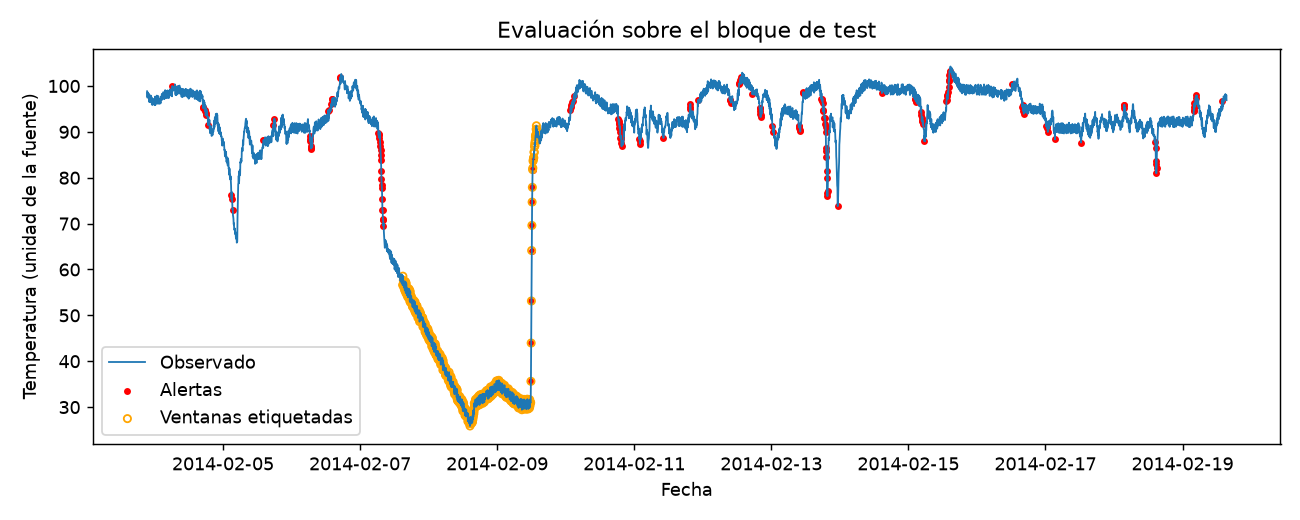

In [2]:
from nab_anomaly_detection.flow import run_stage
metricas, comentario = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comentario))
from nab_anomaly_detection.presentation import display_evaluation
display_evaluation(PROJECT_ROOT, metricas)


## Alertas

Avisos agrupados con descripción y acción sugerida. Los errores no se ocultan; no registrar warnings no garantiza que el análisis sea válido.

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from nab_anomaly_detection.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/AnomalyDetection/NABAnomalyDetection/reports/informe_final/informe_final.md')